In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
file = pd.read_csv("dataset.csv")

In [3]:
file = file.dropna()
file = pd.get_dummies(file, columns=["ocean_proximity"], drop_first=True)

# Rescalling

In [4]:
x_features = file.drop(columns=["median_house_value"])
y_output = file["median_house_value"]

In [5]:
x_features = x_features.to_numpy()
y_output = y_output.to_numpy()

In [6]:
train_set = int(0.9*len(file))

# Using Z-Normalisation
mean = np.mean(x_features[:train_set,:].astype(np.float64), axis=0)
std = np.std(x_features[:train_set,:].astype(np.float64),axis=0)
std[std == 0] = 1.0

x_train = (x_features[:train_set,:].astype(np.float64)-mean)/std
y_train = y_output[:train_set].astype(np.float64).reshape(-1,1)

x_test = (x_features[train_set:,:].astype(np.float64)-mean)/std
y_test = y_output[train_set:].astype(np.float64).reshape(-1,1)

# Evaluation $\vec{w},b$ using gradient descent

$$J_{\vec{w},b}=\frac{1}{2m}\sum(f(\vec{x})-y_i)^2$$

In [7]:
def gradient_descent(x,y,w,b,m,iter):
    a = 0.1
    dw_arr = np.empty(shape=(iter,12))
    db_arr = np.empty(iter)
    for i in range(iter):
        f = x.dot(w) + b

        dj_dw = (1/m)*(x.T @ (f - y))
        dj_db = (1/m)*np.sum(f-y)

        w = w - a*dj_dw
        b = b - a*dj_db

        dw_arr[i,:] = dj_dw.T
        db_arr[i] = dj_db

    return w,b,dw_arr,db_arr


In [8]:
iteration = 10000
w,b,dw,db = gradient_descent(x_train, y_train,np.zeros(shape=(12,1)),0, train_set, iteration)

# Graphing Derivative of cost function with respect to weights

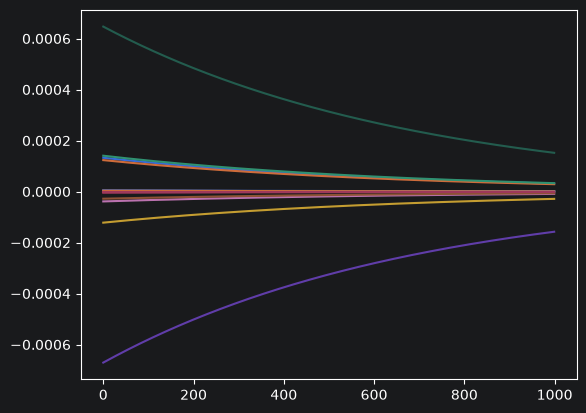

In [14]:
for i in range(12):
    plt.plot(dw[iteration-1000:,i])
plt.plot(db[iteration-1000:])

# Derivatives of all plots are clearly converging to 0

# Comparison of prediction to individual $x_i$ parameters in $\vec{x}$

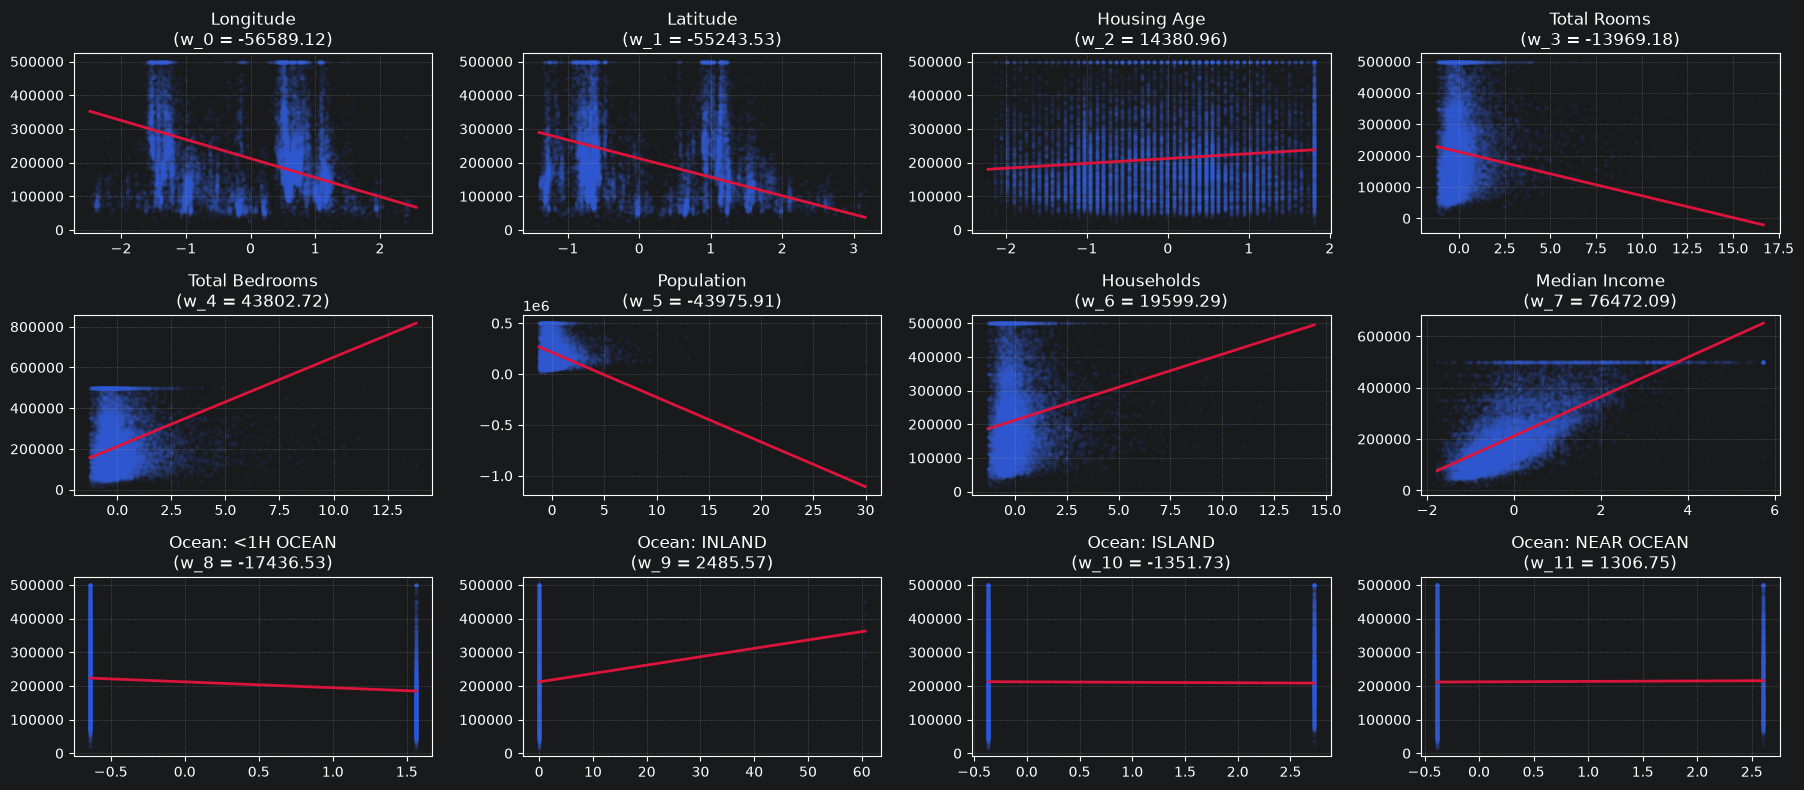

In [10]:
feature_names = [
    "Longitude", "Latitude", "Housing Age", "Total Rooms",
    "Total Bedrooms", "Population", "Households", "Median Income",
    "Ocean: <1H OCEAN", "Ocean: INLAND", "Ocean: ISLAND", "Ocean: NEAR OCEAN"
]

fig, axes = plt.subplots(3, 4, figsize=(18, 8))
axes = axes.flatten()

for i in range(12):
    axes[i].scatter(x_train[:, i], y_train, alpha=0.05, color='royalblue', s=5)

    x_line = np.linspace(x_train[:, i].min(), x_train[:, i].max(), 100)
    y_line = x_line * w[i] + b

    # Plot prediction line
    axes[i].plot(x_line, y_line, color='crimson', linewidth=2)
    axes[i].set_title(f"{feature_names[i]}\n(w_{i} = {w[i][0]:.2f})")
    axes[i].grid(True, linestyle=':', alpha=0.5)

plt.tight_layout()
plt.show()

# Comparison of prediction with $Y_i$ values of specific indices

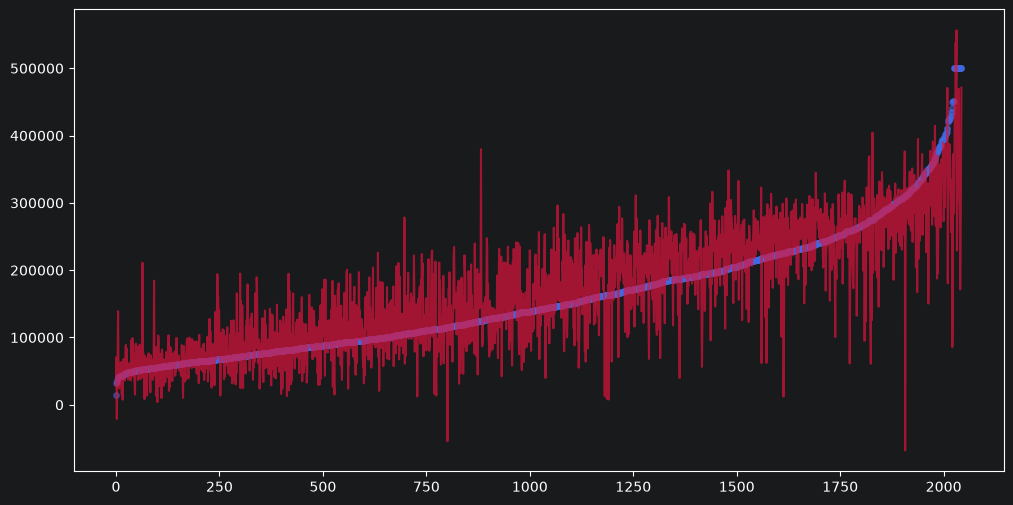

In [11]:
indices = np.argsort(y_test.flatten())
plt.figure(figsize=(12, 6))

f = x_test @ w + b

sorted_y_test = y_test.flatten()[indices]
sorted_y_pred = f.flatten()[indices]

# Plot actual target values as scatter points
plt.plot(sorted_y_pred, color='crimson', alpha=0.7, linewidth=1.5, label='Predicted Values')
plt.scatter(np.arange(len(sorted_y_test)), sorted_y_test, color='royalblue', alpha=0.5, s=15, label='Actual Values')